In [1]:
import pacmap
import umap.umap_                       as umap 
import numpy                            as np
import pandas                           as pd

import seaborn                          as sns
import matplotlib.pyplot                as plt
import matplotlib.gridspec              as gridspec
import plotly.express                   as px
import plotly.graph_objects             as go

from tqdm                               import tqdm
from plotly.subplots                    import make_subplots
from sklearn.preprocessing              import StandardScaler, MinMaxScaler
from sklearn.cluster                    import DBSCAN

from utils.Preprocessing                import PreProcessData
from utils.plotFigures                  import plotResults, plotResultsPlotly, plotLabels
from clustering.plotClustering          import ClusteringResults

In [2]:
preData = PreProcessData()
preData.dataLoading(typeFile='h5')
preData.additionEfficiencyVar()

df              = preData.splitTimeSeries()
dfHealthy       = preData.getHealthyState()

scaler          = MinMaxScaler()
scaledData      = preData.normalizeData(data   = df, 
                                        scaler = scaler) 
scaledHealthy   = preData.normalizeData(data   = dfHealthy, 
                                        scaler = scaler)

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\utils\Preprocessing.py:269: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.healthyData    = pd.concat([self.healthyData, healthyPeriod],     ignore_index=True)
c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\utils\Preprocessing.py:269: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.healthyData    = pd.concat([self.healthyData, healthyPeriod],     ignore_index=True)
c:\Users\CAEX\Desktop\Diego\Crusher 

# Plot time series colored by labels

In [3]:
def assign_labels(data, num_groups=3):
    n       = len(data)
    labels  = np.zeros(n, dtype=int)
    idx     = np.array_split(np.arange(n), num_groups)
    for i, group_idx in enumerate(idx):
        labels[group_idx] = i
    
    return labels

scaledData['label'] = scaledData.groupby('trajectory')['corriente(A)'].transform(assign_labels).astype('str')

In [4]:
plotLabels(dataframe    = scaledData,
           variable     = 'Piñón_ext(°C)')

# Dimensionality Reduction

In [5]:
scaledData['period']    = scaledData['tiempo'].dt.strftime('%d-%m-%Y %H')
scaledHealthy['period'] = scaledHealthy['tiempo'].dt.strftime('%d-%m-%Y %H')

## Idea 1

In [6]:
# Embedding space using healthy data
dfEfficiencyVar = scaledHealthy[preData.efficiencyCr1 + preData.newEfficiencyCr1]

clusteringModels    = {'umap':   DBSCAN(min_samples = 150,
                                        eps         = 2.2)} 

dimReductionModels  = {'umap':   umap.UMAP(n_components = 2,
                                           n_neighbors  = 15, 
                                           random_state = 40)}

EmbeddingHealthy = ClusteringResults(data                = scaledHealthy, 
                                     dataNormalized      = dfEfficiencyVar, 
                                     clusteringModels    = clusteringModels, 
                                     dimReductionModels  = dimReductionModels)

# Train dimensionality reduction model
EmbeddingHealthy.train()


# Embedding space for each trajectory
dfEfficiencyVar     = scaledData[preData.efficiencyCr1 + preData.newEfficiencyCr1]
dimReductionModels  = EmbeddingHealthy.dimReductionModels

Embedding           = ClusteringResults(data                = scaledData, 
                                        dataNormalized      = dfEfficiencyVar, 
                                        clusteringModels    = clusteringModels, 
                                        dimReductionModels  = dimReductionModels)

# Trained embedding space is used
Embedding.embeddingTrain = EmbeddingHealthy.embeddingTrain


# Calculate embedding for all data per each trajectory
for trajectory in tqdm(Embedding.trajectories):
    Embedding.getResults(trajectory)

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\mmodal\Lib\site-packages\umap\umap_.py:1945: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.

100%|██████████| 24/24 [01:37<00:00,  4.08s/it]


## Idea 2

In [7]:
# Embedding space using labels
dfEfficiencyVar = scaledData[preData.efficiencyCr1 + preData.newEfficiencyCr1]

clusteringModels    = {'umap':   DBSCAN(min_samples = 150,
                                        eps         = 2.2)} 

dimReductionModels  = {'umap':   umap.UMAP(n_components = 2,
                                           n_neighbors  = 15, 
                                           random_state = 40)}

Embedding2 = ClusteringResults(data                = scaledData, 
                               dataNormalized      = dfEfficiencyVar, 
                               clusteringModels    = clusteringModels, 
                               dimReductionModels  = dimReductionModels)

# Train dimensionality reduction model
Embedding2.train(supervised=True)

# Get embedding space for each trajectory
for trajectory in tqdm(Embedding2.trajectories):
    Embedding2.getResults(trajectory)

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\mmodal\Lib\site-packages\umap\umap_.py:1945: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.

100%|██████████| 24/24 [02:11<00:00,  5.47s/it]


# Results

## Seaborn

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\utils\plotFigures.py:115: RuntimeWarning:

More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.



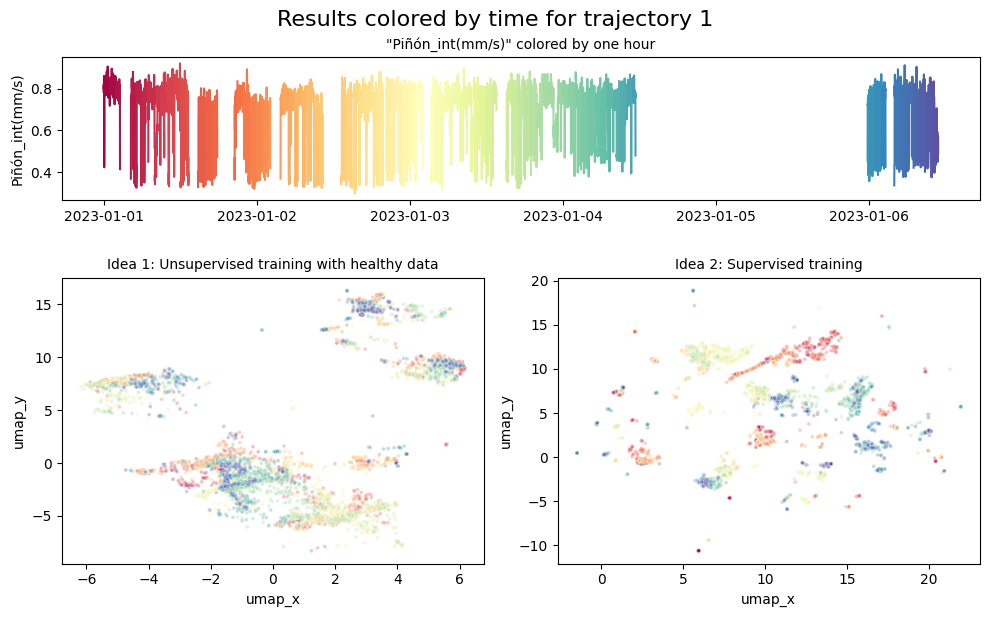

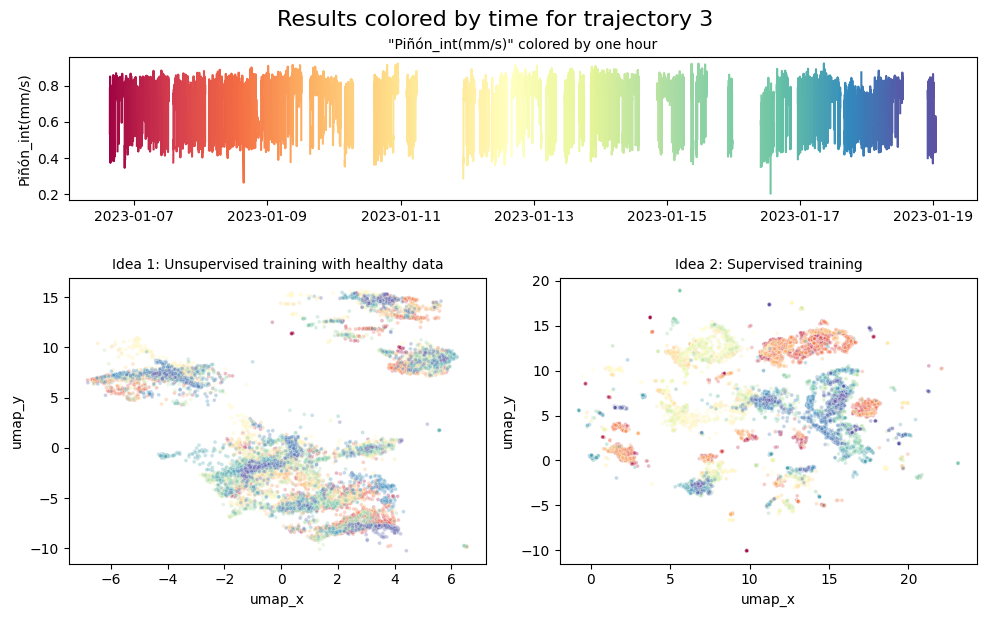

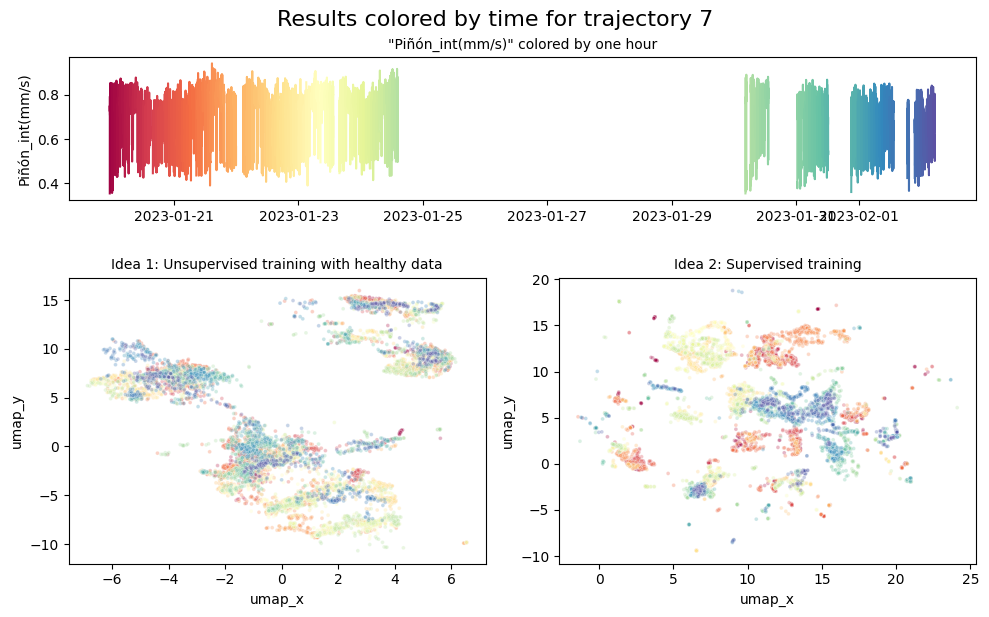

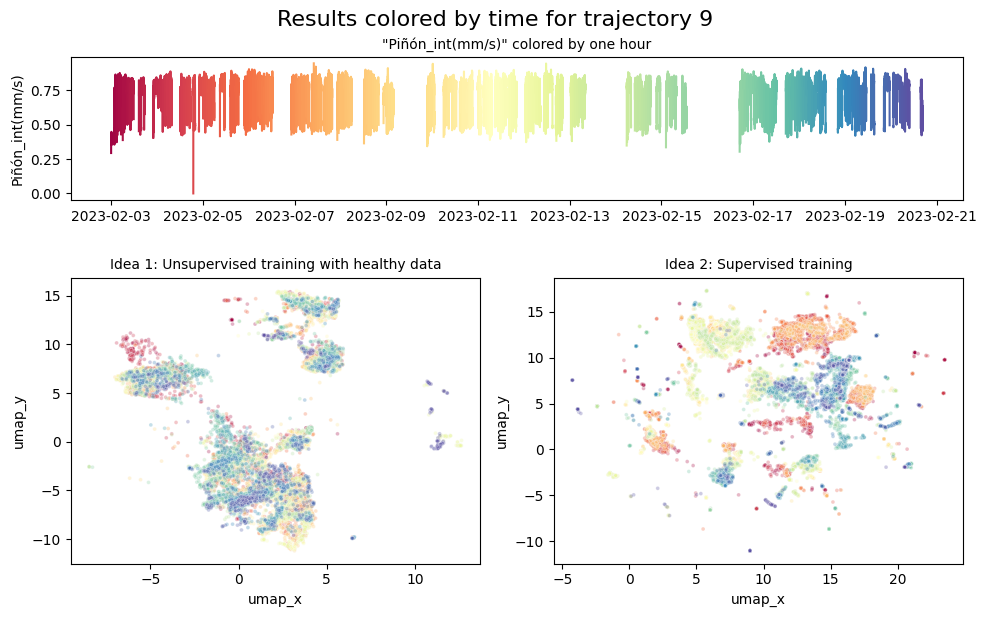

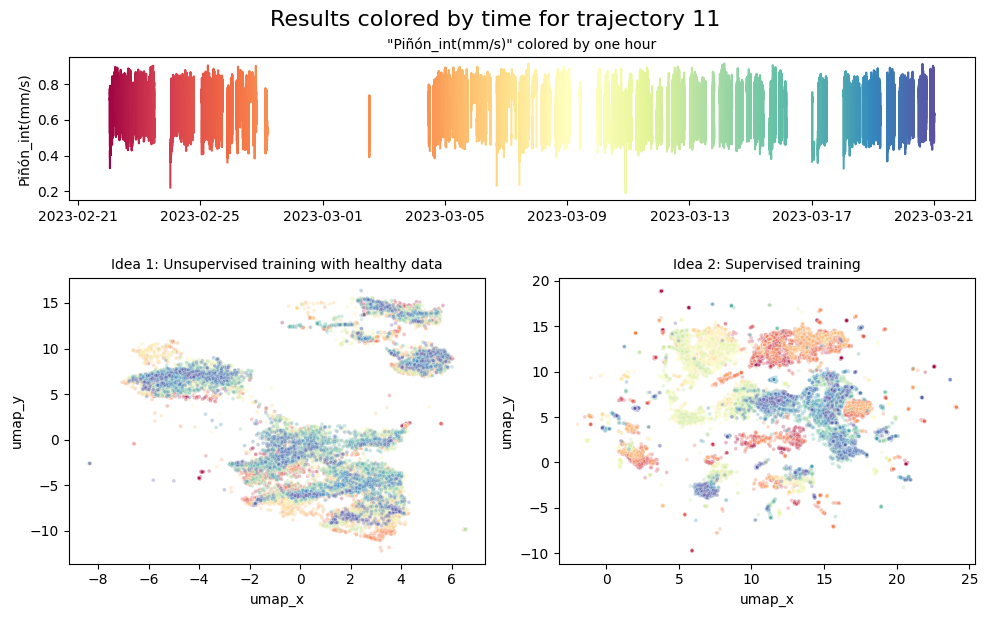

...

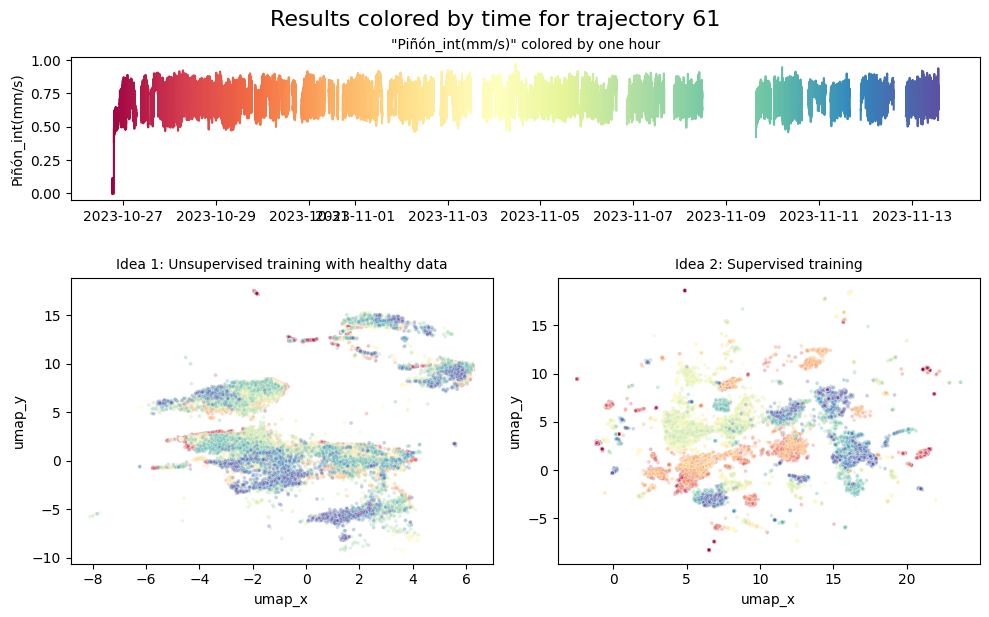

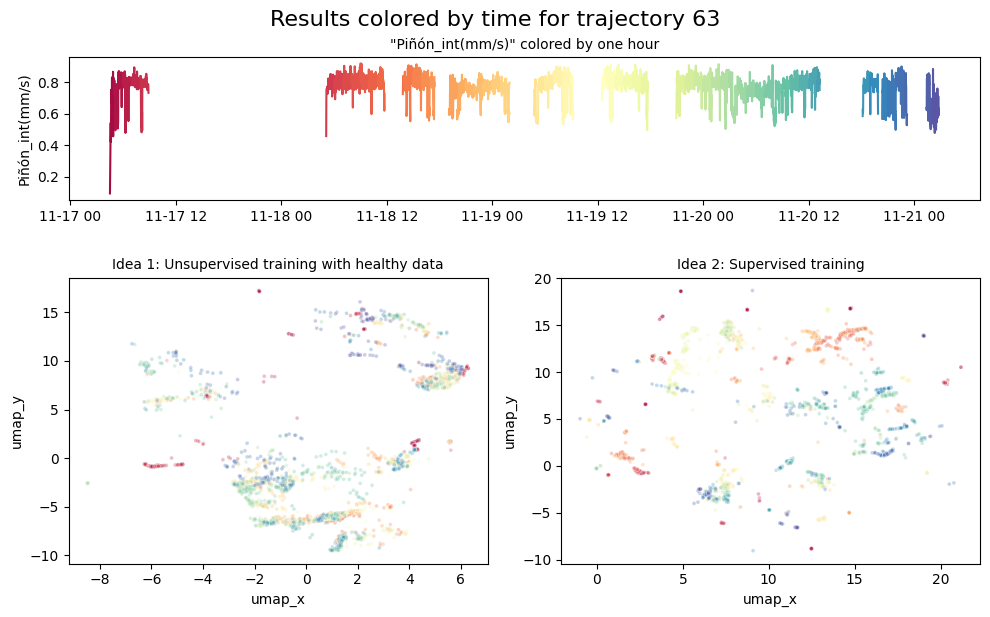

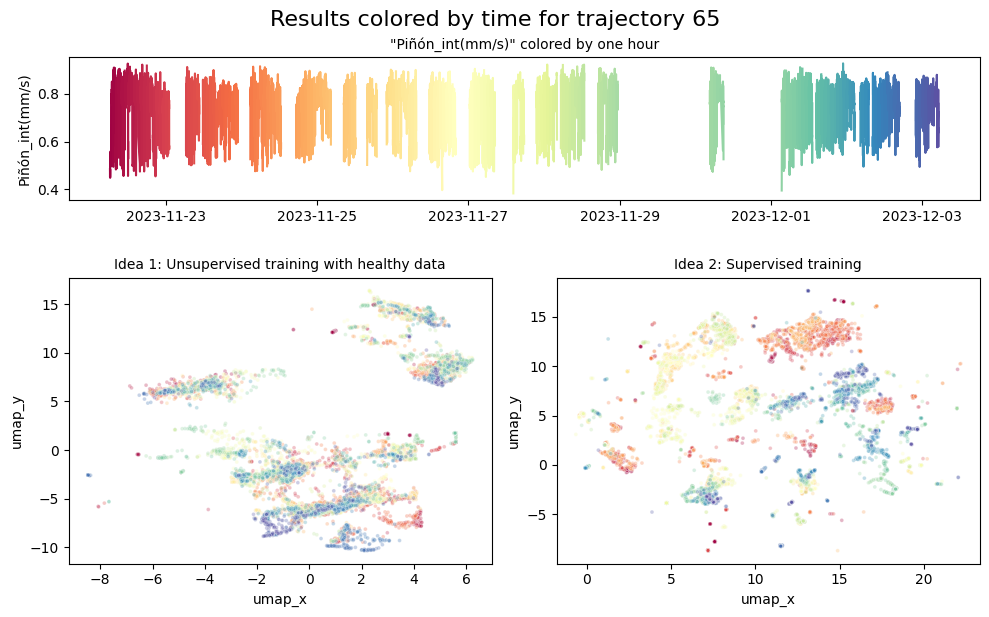

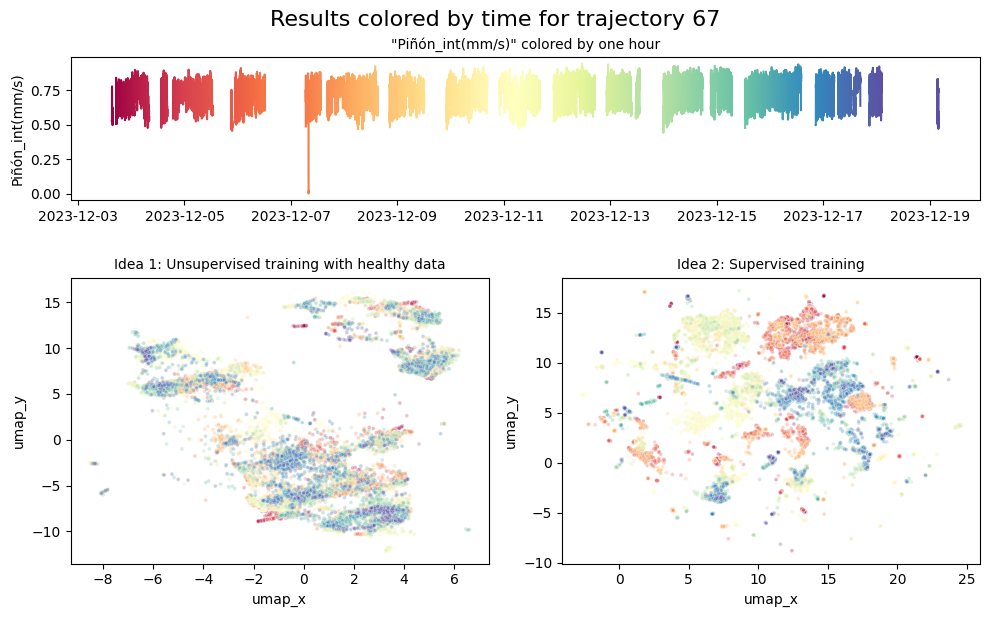

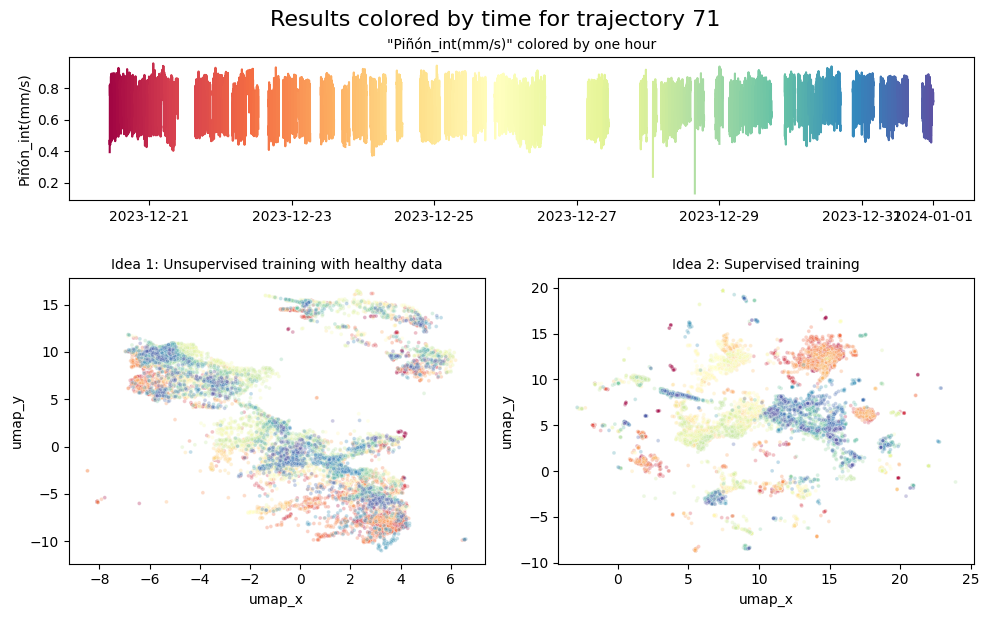

In [11]:
trajectories    = Embedding.trajectories
for trajectory in trajectories:
    # Dataframes
    data1       = Embedding.clustersResults[trajectory]
    data2       = Embedding2.clustersResults[trajectory]
    plotResults(trajectory  = trajectory, 
                data1       = data1, 
                data2       = data2,
                palette     = 'Spectral')
    

## Plotly

In [10]:
trajectory  = '15'
data1       = Embedding.clustersResults[trajectory]
data2       = Embedding2.clustersResults[trajectory]
plotResultsPlotly(trajectory    = trajectory, 
                  data1         = data1, 
                  data2         = data2,
                  palette       = 'Spectral')